In [ ]:
import h5py
import scipy.io
import numpy as np
import os
from google.colab import drive
drive.mount('/content/drive')
src_path = '/content/drive/MyDrive/THINGS_MUA_trials.mat'
map_path = '/content/drive/MyDrive/1024chns_mapping_20220105.mat'
local_cache = '/content/monkeyN_cleaned_normalized.h5'
print("--- Step 1: Loading Mapping ---")
mapping = scipy.io.loadmat(map_path)['mapping'].flatten().astype(int) - 1
good_mapped_indices = np.delete(np.arange(1024), np.arange(320, 384 ))
source_indices = mapping[good_mapped_indices]
print("--- Step 2: High-Speed Load from Drive (~62GB) ---")
with h5py.File(src_path, 'r') as f:
    data = f['ALLMUA'][:]
print("--- Step 3: Reordering and Converting to Float32 ---")
data = data[:, :, source_indices].astype(np.float32)
print("--- Step 4: Rigorous In-Place Z-Scoring ---")
mu = data.mean(axis=(0, 1), keepdims=True)
sigma = data.std(axis=(0, 1), keepdims=True)
data -= mu
data /= (sigma + 1e-9)
print(f"--- Step 5: Caching to Local Runtime ({local_cache}) ---")
with h5py.File(local_cache, 'w') as hf:
    hf.create_dataset('data', data=data, compression=None)
    hf.attrs['ROI_slices'] = "V1: 0-448, V4: 448-704, IT: 704-960"
print("\nPipeline Complete!")
print(f"Final RAM data shape: {data.shape}")
print(f"Local storage used: {os.path.getsize(local_cache) / 1e9:.2f} GB")

Mounted at /content/drive
--- Step 1: Loading Mapping ---
--- Step 2: High-Speed Load from Drive (~62GB) ---
--- Step 3: Reordering and Converting to Float32 ---
--- Step 4: Rigorous In-Place Z-Scoring ---
--- Step 5: Caching to Local Runtime (/content/monkeyN_cleaned_normalized.h5) ---

Pipeline Complete!
Final RAM data shape: (300, 25248, 960)
Local storage used: 29.09 GB


In [ ]:
import h5py
import numpy as np
file_path = '/content/drive/MyDrive/THINGS_MUA_trials.mat'
with h5py.File(file_path, 'r') as f:
    metadata = np.array(f['ALLMAT'])
    trial_nums = metadata[0, :]
    train_ids = metadata[1, :]
    test_ids = metadata[2, :]
    counts = metadata[4, :]
    print(f"--- Dataset Summary ---")
    print(f"Total Stimulus Presentations: {metadata.shape[1]}")
    print("\nFirst 10 Trials Preview:")
    print(f"{'Trial #':<10} | {'Type':<8} | {'Stimulus ID':<12} | {'Seq Position'}")
    print("-" * 50)
    for i in range(10):
        is_train = train_ids[i] != 0
        stim_id = train_ids[i] if is_train else test_ids[i]
        trial_type = "TRAIN" if is_train else "TEST"
        print(f"{int(trial_nums[i]):<10} | {trial_type:<8} | {int(stim_id):<12} | {int(counts[i])}")

--- Dataset Summary ---
Total Stimulus Presentations: 25248

First 10 Trials Preview:
Trial #    | Type     | Stimulus ID  | Seq Position
--------------------------------------------------
1          | TRAIN    | 16504        | 1
2          | TRAIN    | 16470        | 2
3          | TRAIN    | 15094        | 1
4          | TRAIN    | 2514         | 2
5          | TRAIN    | 4860         | 3
6          | TEST     | 27           | 4
7          | TEST     | 5            | 1
8          | TRAIN    | 7629         | 2
9          | TEST     | 64           | 3
10         | TRAIN    | 16848        | 4


In [ ]:
import h5py
import numpy as np
import pandas as pd
import os
mat_mapping_path = '/content/drive/MyDrive/things_imgs.mat'
neural_data_path = '/content/drive/MyDrive/THINGS_MUA_trials.mat'
extract_dir = '/content/drive/MyDrive/THINGS_images_unzipped'
def load_instance_paths(f, group_name, field_name):
    """
    Dereferences the specific field (like 'things_path') from
    the MATLAB v7.3 group.
    """
    dataset = f[group_name][field_name]
    refs = dataset[:].flatten()
    strings = []
    print(f"Dereferencing {len(refs)} items from {group_name}/{field_name}...")
    for ref in refs:
        obj = f[ref]
        s = "".join(chr(c) for c in np.array(obj).flatten()).replace('\\', '/')
        strings.append(s)
    return strings
with h5py.File(mat_mapping_path, 'r') as f:
    train_instances = load_instance_paths(f, 'train_imgs', 'things_path')
    test_instances = load_instance_paths(f, 'test_imgs', 'things_path')
print("Aligning 25,248 trials to instance filenames...")
with h5py.File(neural_data_path, 'r') as f:
    all_mat = f['ALLMAT'][:]
    train_idx = all_mat[1, :].astype(int)
    test_idx = all_mat[2, :].astype(int)
final_paths = []
final_concepts = []
for i in range(25248):
    if train_idx[i] > 0:
        rel_path = train_instances[train_idx[i] - 1]
        is_train = True
    else:
        rel_path = test_instances[test_idx[i] - 1]
        is_train = False
    final_paths.append(os.path.join(extract_dir, rel_path))
    final_concepts.append(rel_path.split('/')[0])
master_metadata = pd.DataFrame({
    'trial_idx': np.arange(25248),
    'concept': final_concepts,
    'relative_path': [p.replace(extract_dir + '/', '') for p in final_paths],
    'full_path': final_paths,
    'is_train': train_idx > 0
})
print(f"\nSuccess! All {len(master_metadata)} trials are matched to instances.")
print(f"Sample Instance: {master_metadata.iloc[0]['relative_path']}")
master_metadata.to_csv('/content/master_metadata.csv', index=False)
print("Saved metadata to /content/master_metadata.csv")

Dereferencing 22248 items from train_imgs/things_path...
Dereferencing 100 items from test_imgs/things_path...
Aligning 25,248 trials to instance filenames...

Success! All 25248 trials are matched to instances.
Sample Instance: scanner/scanner_04s.jpg
Saved metadata to /content/master_metadata.csv


cuML available — GPU PCA enabled
USE_COPULA=True  |  output: /content/drive/MyDrive/neurips_fast_comparison_copula
Bins: 57  |  N_SHUFFLES: 60  |  N_BIAS_SUB: 1500
Loading neural data...
  Loaded: (300, 25248, 960)  (35.5s)
  V1:448  IT:256  V4:256
Resolving image paths...
  Valid images: 25248
  Subset: 3000 trials

Extracting CNN features...

Extracting CNN features (avgpool, subset images only)...
  Device: cuda
  VRAM: 85.1 GB  →  batch size: 3000
  Total images: 3000  |  batches: 1  |  batch size: 3000
    Batch    Done    Left   Elapsed       ETA    img/s
  -------------------------------------------------------
     1/1      3000       0     70.1s      0.0s       43

  Inference done in 70.1s
  avgpool: (3000, 512) → PCA-50 (3000, 50)  (72.3s total)
  cuML PCA failed (__init__() got an unexpected keyword argument 'random_state'), falling back
  avgpool: (3000, 512) → PCA-50 (3000, 50)  (total 74.1s)
MI estimator: Gaussian Copula (GCMI)

MAIN LOOP | avgpool | 57 bins | 3000 trial

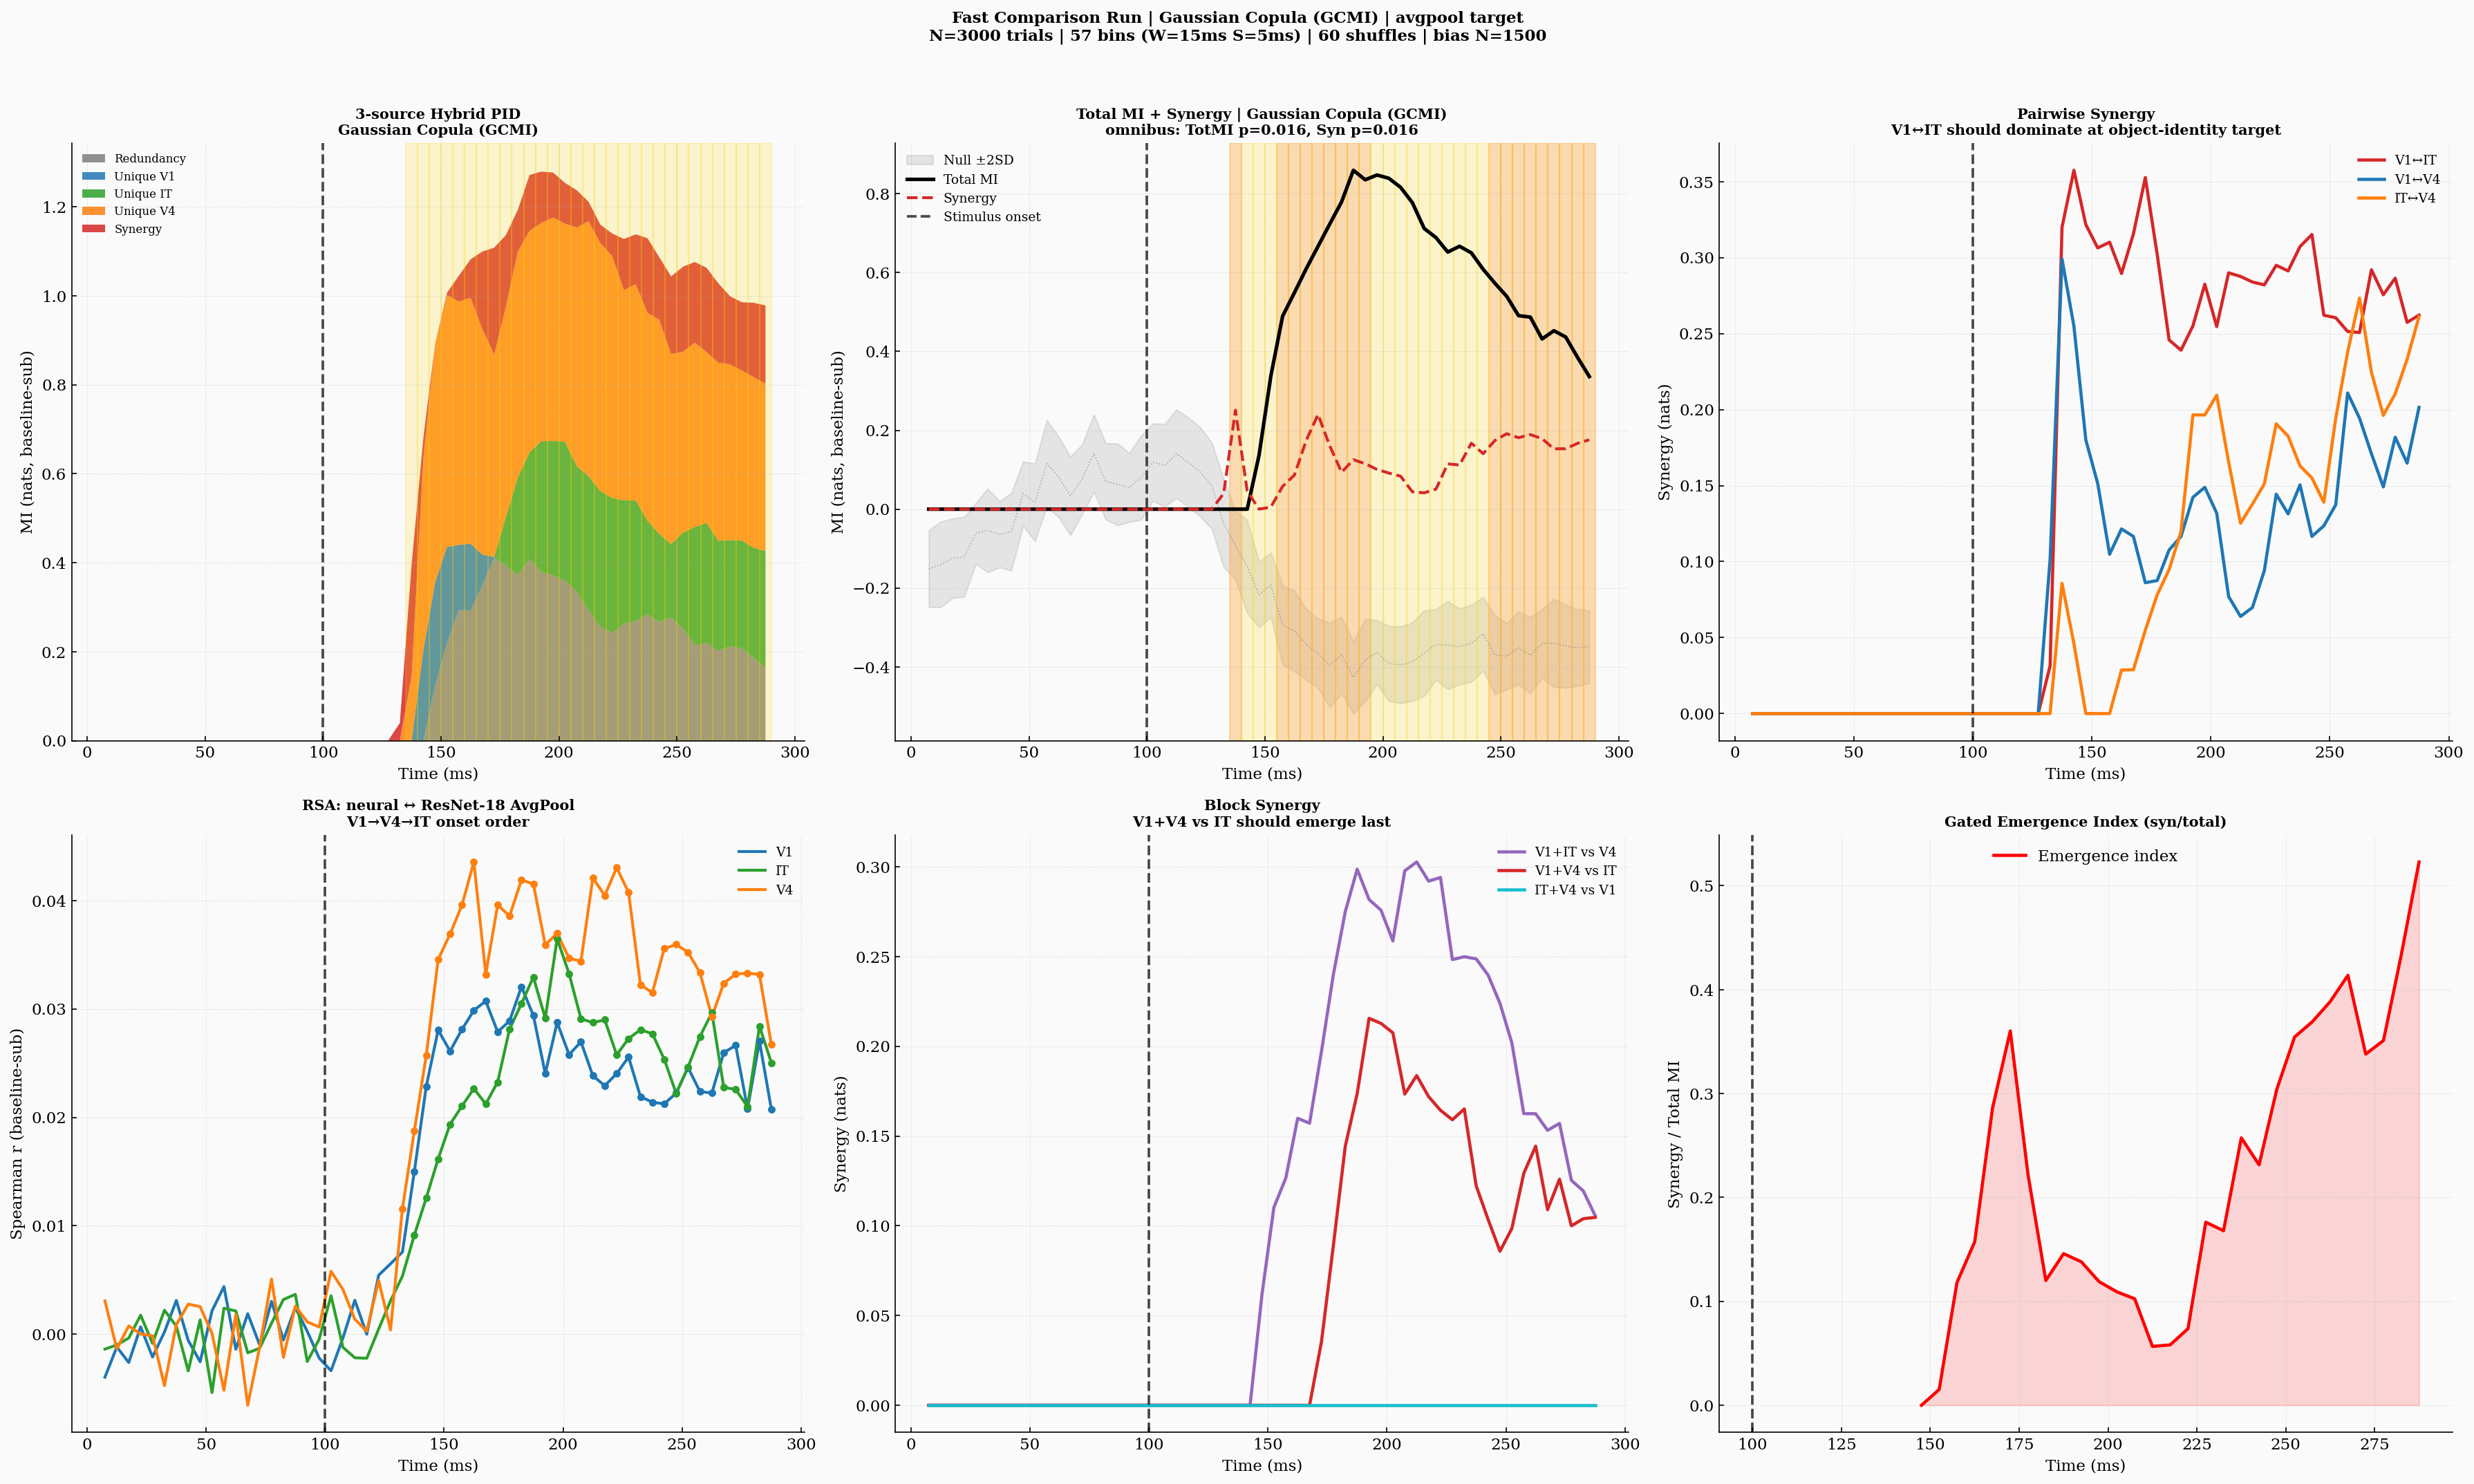


Done. Total time: 26.3 min
Estimator: Gaussian Copula (GCMI)
Output: /content/drive/MyDrive/neurips_fast_comparison_copula
Files:
  fig_comparison.pdf  (53 KB)
  table_block.csv  (5 KB)
  table_pairwise.csv  (5 KB)
  table_pid3.csv  (4 KB)
  table_rsa.csv  (5 KB)
  table_summary.csv  (0 KB)
  table_sweep.csv  (0 KB)


In [ ]:
import os, warnings, time
warnings.filterwarnings("ignore", category=RuntimeWarning)
import numpy as np, pandas as pd, h5py, torch
import torchvision.models as models, torchvision.transforms as T
from torch.utils.data import Dataset, DataLoader
from PIL import Image
from numpy.linalg import slogdet
from scipy.linalg import eigh
from scipy.stats import spearmanr, rankdata
from scipy.stats import norm as sp_norm
from sklearn.decomposition import PCA
import matplotlib, matplotlib.pyplot as plt
matplotlib.rcParams.update({'font.family':'serif','font.size':11,
    'axes.spines.top':False,'axes.spines.right':False,'axes.linewidth':0.8,
    'xtick.direction':'in','ytick.direction':'in','figure.dpi':150})
try:
    from cuml.decomposition import PCA as cuPCA
    import cupy as cp
    CUDA_ML = True
    print("cuML available — GPU PCA enabled")
except ImportError:
    CUDA_ML = False
    print("cuML not available — CPU PCA fallback")
USE_COPULA = True
N_SUBSET            = 3000
N_BIAS_SUB          = 1500
N_SHUFFLES          = 60
STIM_ONSET          = 100
WINDOW_SIZE         = 15
STEP_SIZE           = 5
TIME_BINS           = np.arange(0, 300-WINDOW_SIZE, STEP_SIZE)
EMERGE_GATE_NSEM    = 3.0
CLUSTER_ALPHA       = 0.05
SWEEP_CONFIGS       = [(20,10),(50,10)]
ROIS                = ['V1','IT','V4']
ROI_COLORS          = {'V1':'#1f77b4','IT':'#2ca02c','V4':'#ff7f0e'}
CACHE_PATH  = '/content/monkeyN_cleaned_normalized.h5'
ACTUAL_ROOT = '/content/drive/MyDrive/THINGS_images_unzipped/object_images'
_base       = '/content/drive/MyDrive/neurips_fast_comparison'
DRIVE_OUT   = _base + ('_copula' if USE_COPULA else '_gauss')
os.makedirs(DRIVE_OUT, exist_ok=True)
print(f"USE_COPULA={USE_COPULA}  |  output: {DRIVE_OUT}")
print(f"Bins: {len(TIME_BINS)}  |  N_SHUFFLES: {N_SHUFFLES}  |  N_BIAS_SUB: {N_BIAS_SUB}")
t_grand = time.time()
print("="*60)
print("Loading neural data...")
t0 = time.time()
with h5py.File(CACHE_PATH,'r') as hf:
    clean_data = hf['data'][:].astype(np.float64)
T_total, N_trials, N_units = clean_data.shape
print(f"  Loaded: {clean_data.shape}  ({time.time()-t0:.1f}s)")
assert N_units==960 and T_total==300 and N_trials>=25000
roi_clean = {'V1': clean_data[:,:,0:448],
             'IT': clean_data[:,:,704:960],
             'V4': clean_data[:,:,448:704]}
print(f"  V1:{roi_clean['V1'].shape[2]}  IT:{roi_clean['IT'].shape[2]}  V4:{roi_clean['V4'].shape[2]}")
print("Resolving image paths...")
master_metadata['full_path'] = master_metadata['relative_path'].apply(
    lambda x: os.path.join(ACTUAL_ROOT, x))
valid_metadata = (master_metadata[master_metadata['full_path'].apply(os.path.exists)]
                  .copy().reset_index(drop=True))
print(f"  Valid images: {len(valid_metadata)}")
rng_subset = np.random.default_rng(42)
subset_pos = rng_subset.choice(len(valid_metadata), N_SUBSET, replace=False)
trials_all = valid_metadata['trial_idx'].values[subset_pos]
paths_sub  = valid_metadata['full_path'].values[subset_pos]
print(f"  Subset: {len(trials_all)} trials")
print("\nExtracting CNN features...")
import nvidia.dali.pipeline as dali_pipe
import nvidia.dali.fn as fn
import nvidia.dali.types as types
from nvidia.dali.plugin.pytorch import DALIGenericIterator
print("\nExtracting CNN features (avgpool, subset images only)...")
class THINGSDs(Dataset):
    def __init__(self, paths, tf): self.paths, self.tf = paths, tf
    def __len__(self): return len(self.paths)
    def __getitem__(self, i):
        try:
            with Image.open(self.paths[i]) as img:
                return self.tf(img.convert('RGB'))
        except:
            return torch.zeros(3, 224, 224)
device = "cuda" if torch.cuda.is_available() else "cpu"
print(f"  Device: {device}")
if device == "cuda":
    vram_gb = torch.cuda.get_device_properties(0).total_memory / 1e9
    BATCH = 3000 if vram_gb >= 70 else 512 if vram_gb >= 30 else 512 if vram_gb >= 16 else 512
else:
    BATCH = 512
print(f"  VRAM: {vram_gb:.1f} GB  →  batch size: {BATCH}")
mdl = models.resnet18(weights='DEFAULT').to(device).eval()
avgpool_buf = []
def _hook(m, i, o):
    avgpool_buf.append(o.view(o.size(0), -1).detach().cpu().numpy())
h = mdl.avgpool.register_forward_hook(_hook)
tf_cpu = T.Compose([
    T.Resize(256),
    T.CenterCrop(224),
    T.ToTensor(),
    T.Normalize([0.485,0.456,0.406],[0.229,0.224,0.225])
])
dl = DataLoader(
    THINGSDs(paths_sub, tf_cpu),
    batch_size=BATCH,
    num_workers=0,
    pin_memory=True,
)
n_batches = len(dl)
print(f"  Total images: {len(paths_sub)}  |  batches: {n_batches}  |  batch size: {BATCH}")
print(f"  {'Batch':>7}  {'Done':>6}  {'Left':>6}  {'Elapsed':>8}  {'ETA':>8}  {'img/s':>7}")
print(f"  {'-'*55}")
t0 = time.time()
with torch.no_grad(), torch.autocast(device_type='cuda', dtype=torch.float16):
    for b_idx, b in enumerate(dl):
        mdl(b.to(device, non_blocking=True))
        elapsed = time.time() - t0
        done    = b_idx + 1
        left    = n_batches - done
        imgs_done = min(done * BATCH, len(paths_sub))
        img_s   = imgs_done / elapsed
        eta     = (elapsed / done) * left
        print(f"  {done:>4}/{n_batches:<3}  {imgs_done:>6}  {len(paths_sub)-imgs_done:>6}  "
              f"{elapsed:>7.1f}s  {eta:>7.1f}s  {img_s:>7.0f}")
h.remove()
print(f"\n  Inference done in {time.time()-t0:.1f}s")
raw_cnn   = np.vstack(avgpool_buf).astype(np.float64)
cnn_feats = PCA(n_components=50).fit_transform(raw_cnn)
print(f"  avgpool: {raw_cnn.shape} → PCA-50 {cnn_feats.shape}  ({time.time()-t0:.1f}s total)")
print("="*60)
t1 = time.time()
raw_cnn_f64 = raw_cnn.astype(np.float64)
if CUDA_ML:
    try:
        pca_gpu   = cuPCA(n_components=50, random_state=0)
        cnn_feats = cp.asnumpy(pca_gpu.fit_transform(cp.asarray(raw_cnn)))
        print(f"  PCA: cuML GPU  ({time.time()-t1:.2f}s)")
    except Exception as e:
        print(f"  cuML PCA failed ({e}), falling back")
        cnn_feats = PCA(n_components=50, svd_solver='randomized',
                        random_state=0).fit_transform(raw_cnn_f64)
else:
    try:
        X_t   = torch.from_numpy(raw_cnn).to(device)
        X_t   = X_t - X_t.mean(0)
        _, _, Vt = torch.linalg.svd(X_t, full_matrices=False)
        cnn_feats = (X_t @ Vt[:50].T).cpu().numpy().astype(np.float64)
        del X_t, Vt
        torch.cuda.empty_cache()
        print(f"  PCA: torch SVD GPU  ({time.time()-t1:.2f}s)")
    except Exception:
        cnn_feats = PCA(n_components=50, svd_solver='randomized',
                        random_state=0).fit_transform(raw_cnn_f64)
        print(f"  PCA: sklearn fallback  ({time.time()-t1:.2f}s)")
cnn_feats = np.asarray(cnn_feats, dtype=np.float64)
print(f"  avgpool: {raw_cnn.shape} → PCA-50 {cnn_feats.shape}  "
      f"(total {time.time()-t0:.1f}s)")
print("="*60)
def mp_pca(X):
    X  = np.asarray(X, dtype=np.float32)
    n, p = X.shape
    Xc = (X - X.mean(0)).astype(np.float64)
    if CUDA_ML and p > 50:
        try:
            n_comp = min(p-1, n-1, 512)
            pca_gpu = cuPCA(n_components=n_comp, random_state=0)
            pca_gpu.fit(cp.asarray(Xc.astype(np.float32)))
            lam  = cp.asnumpy(pca_gpu.explained_variance_).astype(np.float64)
            vecs = cp.asnumpy(pca_gpu.components_).T.astype(np.float64)
        except Exception:
            cov = np.cov(Xc, rowvar=False)
            la, ve = eigh(cov); lam = la[::-1]; vecs = ve[:,::-1]
    else:
        cov = np.cov(Xc, rowvar=False)
        la, ve = eigh(cov); lam = la[::-1]; vecs = ve[:,::-1]
    gamma    = p / n
    sigma2   = float(np.median(lam[lam>0]))
    lam_plus = sigma2 * (1.0 + np.sqrt(gamma))**2
    k        = max(1, int(np.sum(lam > lam_plus)))
    return Xc @ vecs[:,:k], k, lam
def mp_pca_from_pcs(pc_list):
    X  = np.hstack(pc_list).astype(np.float64)
    Xc = X - X.mean(0)
    cov = np.cov(Xc, rowvar=False)
    la, ve = eigh(cov); lam = la[::-1]; vecs = ve[:,::-1]
    gamma    = X.shape[1] / X.shape[0]
    sigma2   = float(np.median(lam[lam>0]))
    lam_plus = sigma2 * (1.0 + np.sqrt(gamma))**2
    k        = max(1, int(np.sum(lam > lam_plus)))
    return Xc @ vecs[:,:k], k, lam
def _mi_gauss_plugin(X, Y):
    X  = np.asarray(X, dtype=np.float64); Xc = X - X.mean(0)
    Y  = np.asarray(Y, dtype=np.float64); Yc = Y - Y.mean(0)
    n  = len(Xc); dx = Xc.shape[1]
    XY = np.hstack([Xc, Yc]); C = (XY.T @ XY) / (n-1)
    Cx = C[:dx,:dx]; Cy = C[dx:,dx:]
    sx, ldx = slogdet(Cx); sy, ldy = slogdet(Cy); sc, ldc = slogdet(C)
    if sx<=0 or sy<=0 or sc<=0: return 0.0
    return max(0.0, 0.5*(ldx+ldy-ldc))
def _mi_gauss_batch_shuffles_plugin(X, Y, n_sh=N_SHUFFLES, rng=None):
    if rng is None: rng = np.random.default_rng()
    X  = np.asarray(X, dtype=np.float64); Xc = X - X.mean(0)
    Y  = np.asarray(Y, dtype=np.float64)
    n  = len(Xc); dx = Xc.shape[1]
    Cxx = (Xc.T @ Xc) / (n-1)
    sx, ldx = slogdet(Cxx)
    if sx <= 0: return np.zeros(n_sh)
    mis = np.zeros(n_sh)
    for sh in range(n_sh):
        Ys = Y[rng.permutation(n)]; Yc = Ys - Ys.mean(0)
        XY = np.hstack([Xc, Yc]); C = (XY.T @ XY) / (n-1)
        Cy = C[dx:,dx:]
        sy, ldy = slogdet(Cy); sc, ldc = slogdet(C)
        if sy<=0 or sc<=0: mis[sh]=0.0
        else: mis[sh] = max(0.0, 0.5*(ldx+ldy-ldc))
    return mis
def _gaussianize(Z):
    Z = np.asarray(Z, dtype=np.float64)
    ranks = rankdata(Z, axis=0)
    return sp_norm.ppf((ranks - 0.5) / Z.shape[0])
def _mi_copula_gauss(X, Y):
    return _mi_gauss_plugin(_gaussianize(X), Y)
def _mi_copula_gauss_batch_shuffles(X, Y, n_sh=N_SHUFFLES, rng=None):
    Xg = _gaussianize(np.asarray(X, dtype=np.float64))
    return _mi_gauss_batch_shuffles_plugin(Xg, Y, n_sh=n_sh, rng=rng)
if USE_COPULA:
    _mi_gauss                = _mi_copula_gauss
    _mi_gauss_batch_shuffles = _mi_copula_gauss_batch_shuffles
    print("MI estimator: Gaussian Copula (GCMI)")
else:
    _mi_gauss                = _mi_gauss_plugin
    _mi_gauss_batch_shuffles = _mi_gauss_batch_shuffles_plugin
    print("MI estimator: Gaussian plug-in")
def get_bias(S_list, T, n_sh=N_SHUFFLES, n_sub=N_BIAS_SUB, rng=None):
    if rng is None: rng = np.random.default_rng()
    n   = len(T); idx = rng.choice(n, min(n_sub,n), replace=False)
    Ss  = [S[idx] for S in S_list]; Ts = T[idx]
    bm  = np.zeros(len(S_list)); nm = np.zeros((len(S_list),n_sh))
    bt  = 0.0;                    nt = np.zeros(n_sh)
    for sh in range(n_sh):
        perm = rng.permutation(len(Ts)); Tp = Ts[perm]
        mv   = np.array([_mi_gauss(S, Tp) for S in Ss])
        mj   = _mi_gauss(np.hstack(Ss), Tp)
        bm  += mv; bt += mj; nm[:,sh] = mv; nt[sh] = mj
    return bm/n_sh, bt/n_sh, nm, nt
def get_bias_single(Z, T, n_sh=N_SHUFFLES, n_sub=N_BIAS_SUB, rng=None):
    if rng is None: rng = np.random.default_rng()
    n   = len(T); idx = rng.choice(n, min(n_sub,n), replace=False)
    Zs  = Z[idx]; Ts = T[idx]
    nt  = _mi_gauss_batch_shuffles(Zs, Ts, n_sh=n_sh, rng=rng)
    return float(np.mean(nt)), nt
def hybrid_pid(S_perpc, Z_joint, T, bias_mis, bias_total_perpc, bias_total_joint):
    mis         = np.maximum(0.0, np.array([_mi_gauss(S,T) for S in S_perpc]) - bias_mis)
    mi_joint    = max(0.0, _mi_gauss(Z_joint,T) - bias_total_joint)
    red         = float(np.min(mis))
    uniques     = [max(0.0, float(m)-red) for m in mis]
    syn         = max(0.0, mi_joint - red - sum(uniques))
    total_perpc = max(0.0, _mi_gauss(np.hstack(S_perpc),T) - bias_total_perpc)
    return {'Total':total_perpc,'Redundancy':red,'Synergy':syn,
            'Uniques':uniques,'MI_joint':mi_joint}
def block_pid(Z_pj, Z_lo, T, bias_mis2, bias_total_2src, bias_total_bj):
    Z_bj  = np.hstack([Z_pj, Z_lo])
    mis   = np.maximum(0.0, np.array([_mi_gauss(S,T) for S in [Z_pj,Z_lo]]) - bias_mis2)
    mi_bj = max(0.0, _mi_gauss(Z_bj,T) - bias_total_bj)
    mi_2s = max(0.0, _mi_gauss(Z_bj,T) - bias_total_2src)
    red   = float(np.min(mis))
    syn   = max(0.0, mi_bj - red - max(0.,float(mis[0])-red) - max(0.,float(mis[1])-red))
    return {'Total':mi_2s,'Redundancy':red,'Synergy':syn,
            'Unique_pair':max(0.,float(mis[0])-red),'Unique_lo':max(0.,float(mis[1])-red)}
def pairwise_pid(S_A, S_B, Z_pj, T, bias_mis2, bias_total_2src, bias_total_pj):
    mis   = np.maximum(0.0, np.array([_mi_gauss(S,T) for S in [S_A,S_B]]) - bias_mis2)
    mi_pj = max(0.0, _mi_gauss(Z_pj,T) - bias_total_pj)
    mi_2s = max(0.0, _mi_gauss(np.hstack([S_A,S_B]),T) - bias_total_2src)
    red   = float(np.min(mis))
    syn   = max(0.0, mi_pj - red - max(0.,float(mis[0])-red) - max(0.,float(mis[1])-red))
    return {'Total':mi_2s,'Redundancy':red,'Synergy':syn,
            'Unique_A':max(0.,float(mis[0])-red),'Unique_B':max(0.,float(mis[1])-red)}
def get_rsa_permtest(Xn, Xc, n_sub=300, n_rep=3, n_perm=100, seed=None):
    rng = np.random.default_rng(seed)
    n   = min(len(Xn), len(Xc)); rs=[]
    for _ in range(n_rep):
        idx = rng.choice(n, n_sub, replace=False)
        A = (Xn[idx]-Xn[idx].mean(0))/(Xn[idx].std(0)+1e-8)
        B = (Xc[idx]-Xc[idx].mean(0))/(Xc[idx].std(0)+1e-8)
        rdA=1-np.corrcoef(A); rdB=1-np.corrcoef(B)
        ti,tj=np.triu_indices(n_sub,k=1)
        r,_=spearmanr(rdA[ti,tj],rdB[ti,tj]); rs.append(float(r))
    obs_r=float(np.mean(rs)); null_rs=[]
    idx_p=rng.choice(n,n_sub,replace=False)
    A_p=(Xn[idx_p]-Xn[idx_p].mean(0))/(Xn[idx_p].std(0)+1e-8)
    rdA_p=1-np.corrcoef(A_p)
    for _ in range(n_perm):
        shuf=rng.permutation(n_sub)
        B_s=(Xc[idx_p[shuf]]-Xc[idx_p[shuf]].mean(0))/(Xc[idx_p[shuf]].std(0)+1e-8)
        rdB_s=1-np.corrcoef(B_s)
        r_null,_=spearmanr(rdA_p[ti,tj],rdB_s[ti,tj]); null_rs.append(float(r_null))
    pval=(np.sum(np.array(null_rs)>=obs_r)+1)/(n_perm+1)
    return obs_r, pval
def run_significance(null_mat_raw, obs_arr, pre_mask, post_mask, label=''):
    pre_mean  = null_mat_raw[pre_mask,:].mean(axis=0)
    null_mat  = null_mat_raw - pre_mean[np.newaxis,:]
    null_mean_pb = null_mat.mean(axis=1); null_std_pb = null_mat.std(axis=1)
    obs_mean   = float(np.mean(obs_arr[post_mask]))
    null_means = np.mean(null_mat[post_mask,:], axis=0)
    omni_pval  = (np.sum(null_means >= obs_mean)+1) / (null_mat.shape[1]+1)
    threshold  = null_mean_pb + 2.0*null_std_pb
    masses=[]
    for rep in range(null_mat.shape[1]):
        s=null_mat[:,rep]; sig=s>threshold
        mx=0.0; inc=False; cur=0.0
        for v,f in zip(s,sig):
            if f: cur+=abs(float(v)); inc=True
            else:
                if inc: mx=max(mx,cur)
                cur=0.0; inc=False
        if inc: mx=max(mx,cur)
        masses.append(mx)
    null_arr=np.array(masses)
    clusters=[]; in_cl=False; start=0
    for i,v in enumerate(obs_arr):
        if v>threshold[i] and not in_cl: in_cl=True; start=i
        elif (v<=threshold[i] or i==len(obs_arr)-1) and in_cl:
            clusters.append((start, i-1 if v<=threshold[i] else i)); in_cl=False
    if in_cl: clusters.append((start,len(obs_arr)-1))
    clo=[]; clp=[]; clpv=[]; sig_mask=np.zeros(len(obs_arr),dtype=bool)
    for s,e in clusters:
        mass=float(np.sum(obs_arr[s:e+1]))
        pval=(np.sum(null_arr>=mass)+1)/(len(null_arr)+1)
        clo.append(s); clp.append(s+int(np.argmax(obs_arr[s:e+1]))); clpv.append(pval)
        if pval<CLUSTER_ALPHA: sig_mask[s:e+1]=True
    n_sig=sum(p<CLUSTER_ALPHA for p in clpv)
    print(f"    [{label}] omnibus p={omni_pval:.4f}  clusters={len(clo)}  "
          f"sig={n_sig}  sig_bins={sig_mask.sum()}/{len(sig_mask)}")
    return dict(null_mean_pb=null_mean_pb, null_std_pb=null_std_pb,
                omni_pval=omni_pval, omni_mean=obs_mean,
                clo=clo, clp=clp, clpv=clpv, sig_mask=sig_mask)
def add_stim(ax, label=True):
    ax.axvline(STIM_ONSET,color='black',ls='--',lw=1.8,alpha=0.7,zorder=5,
               label='Stimulus onset' if label else None)
def shade_sig(ax, ta, mask, color='gold', alpha=0.25):
    for i,s in enumerate(mask):
        if s: ax.axvspan(ta[i]-STEP_SIZE/2,ta[i]+STEP_SIZE/2,
                         color=color,alpha=alpha,zorder=1)
def shade_null_band(ax, t_axis, null_mean, null_std, n_sd=2):
    upper=null_mean+n_sd*null_std; lower=null_mean-n_sd*null_std
    ax.fill_between(t_axis,lower,upper,color='grey',alpha=0.18,
                    label=f'Null ±{n_sd}SD',zorder=0)
    ax.plot(t_axis,null_mean,color='grey',lw=0.8,ls=':',alpha=0.6)
def save_csv(df, fname):
    df.to_csv(os.path.join(DRIVE_OUT,fname),index=False)
    print(f"  Saved: {fname}  ({len(df)} rows)")
def save_fig(fig, fname):
    fig.savefig(os.path.join(DRIVE_OUT,fname),bbox_inches='tight',dpi=150)
    print(f"  Saved: {fname}")
n_tbins = len(TIME_BINS)
print("\n"+"="*60)
print(f"MAIN LOOP | avgpool | {n_tbins} bins | {N_SUBSET} trials")
print("="*60)
rng = np.random.default_rng(0)
rsa_res         = {r:{'r':[],'pval':[]} for r in ROIS}
neu2img         = []
null_total_list = [[] for _ in range(n_tbins)]
null_syn_list   = [[] for _ in range(n_tbins)]
block_pid_res   = {'V1IT_vs_V4':[],'V1V4_vs_IT':[],'ITV4_vs_V1':[]}
pair_pid_res    = {'V1_IT':[],'V1_V4':[],'IT_V4':[]}
mp_k_joint      = []
t_loop = time.time()
for t_idx, t in enumerate(TIME_BINS):
    raw    = {roi: np.mean(roi_clean[roi][t:t+WINDOW_SIZE,trials_all,:],
                           axis=0).astype(np.float64) for roi in ROIS}
    pc_roi = {roi: mp_pca(raw[roi])[0] for roi in ROIS}
    for roi in ROIS:
        r_val,pval = get_rsa_permtest(pc_roi[roi], cnn_feats,
                                      n_sub=300, n_rep=3, n_perm=100, seed=t_idx*100)
        rsa_res[roi]['r'].append(r_val); rsa_res[roi]['pval'].append(pval)
    S_perpc        = [pc_roi[r] for r in ROIS]
    Z_joint3,k_j,_ = mp_pca_from_pcs(S_perpc)
    mp_k_joint.append(k_j)
    bm3,bt3_perpc,nm3,nt3 = get_bias(S_perpc, cnn_feats, rng=rng)
    bt3_joint,_           = get_bias_single(Z_joint3, cnn_feats, rng=rng)
    pid3 = hybrid_pid(S_perpc, Z_joint3, cnn_feats, bm3, bt3_perpc, bt3_joint)
    neu2img.append(pid3)
    null_total_list[t_idx].extend(nt3.tolist())
    null_syn_list[t_idx].extend([
        max(0.0, nt3[sh] - np.sum([max(0.,float(m)-float(np.min(nm3[:,sh])))
                                   for m in nm3[:,sh]]) - float(np.min(nm3[:,sh])))
        for sh in range(N_SHUFFLES)])
    block_configs = {'V1IT_vs_V4':(['V1','IT'],'V4'),
                     'V1V4_vs_IT':(['V1','V4'],'IT'),
                     'ITV4_vs_V1':(['IT','V4'],'V1')}
    roi_idx = {'V1':0,'IT':1,'V4':2}
    for bk,(pair_rois,lo_roi) in block_configs.items():
        Z_pj,_,_ = mp_pca_from_pcs([pc_roi[r] for r in pair_rois])
        Z_lo      = pc_roi[lo_roi]
        bm2,bt2,_,_ = get_bias([Z_pj,Z_lo], cnn_feats, rng=rng)
        bt_bj,_     = get_bias_single(np.hstack([Z_pj,Z_lo]), cnn_feats, rng=rng)
        block_pid_res[bk].append(block_pid(Z_pj,Z_lo,cnn_feats,bm2,bt2,bt_bj))
    pair_configs = {'V1_IT':('V1','IT'),'V1_V4':('V1','V4'),'IT_V4':('IT','V4')}
    for pk,(rA,rB) in pair_configs.items():
        Z_p2,_,_ = mp_pca_from_pcs([pc_roi[rA],pc_roi[rB]])
        bias_m    = np.array([bm3[roi_idx[rA]],bm3[roi_idx[rB]]])
        bt_2src   = float(np.mean([bm3[roi_idx[rA]],bm3[roi_idx[rB]]]))
        bt_pj,_   = get_bias_single(Z_p2, cnn_feats, rng=rng)
        pair_pid_res[pk].append(
            pairwise_pid(pc_roi[rA],pc_roi[rB],Z_p2,cnn_feats,bias_m,bt_2src,bt_pj))
    elapsed=time.time()-t_loop; eta=(elapsed/(t_idx+1))*(n_tbins-t_idx-1)
    if (t_idx+1)%5==0 or t_idx==0:
        print(f"    bin {t_idx+1}/{n_tbins}  t={t}ms  "
              f"elapsed={elapsed:.0f}s  ETA={eta:.0f}s")
print(f"  Loop done in {(time.time()-t_loop)/60:.1f} min")
t_axis = TIME_BINS + WINDOW_SIZE/2.0
pre    = t_axis < STIM_ONSET
post   = t_axis >= STIM_ONSET
t_post = t_axis[post]
def _bs(arr):
    b=float(np.mean(arr[pre])) if np.any(pre) else 0.0; return arr-b
rsa_r   = {r: _bs(np.array(rsa_res[r]['r']))  for r in ROIS}
rsa_pv  = {r: np.array(rsa_res[r]['pval'])    for r in ROIS}
rsa_sig = {r: rsa_pv[r] < 0.05               for r in ROIS}
tot_arr = _bs(np.array([p['Total']      for p in neu2img]))
red_arr = _bs(np.array([p['Redundancy'] for p in neu2img]))
syn_arr = _bs(np.array([p['Synergy']    for p in neu2img]))
uv1_arr = _bs(np.array([p['Uniques'][0] for p in neu2img]))
uit_arr = _bs(np.array([p['Uniques'][1] for p in neu2img]))
uv4_arr = _bs(np.array([p['Uniques'][2] for p in neu2img]))
def blk(bk,c): return _bs(np.array([p[c] for p in block_pid_res[bk]]))
blk_syn   = {bk: blk(bk,'Synergy')     for bk in block_pid_res}
blk_red   = {bk: blk(bk,'Redundancy')  for bk in block_pid_res}
blk_upair = {bk: blk(bk,'Unique_pair') for bk in block_pid_res}
blk_ulo   = {bk: blk(bk,'Unique_lo')   for bk in block_pid_res}
def pw(pk,c): return _bs(np.array([p[c] for p in pair_pid_res[pk]]))
pair_syn = {pk: pw(pk,'Synergy')    for pk in pair_pid_res}
pair_red = {pk: pw(pk,'Redundancy') for pk in pair_pid_res}
pre_std = float(np.std(tot_arr[pre])+1e-9)
em_arr  = np.where(tot_arr > EMERGE_GATE_NSEM*pre_std,
                   syn_arr/np.maximum(tot_arr,1e-12), np.nan)
print("  Significance tests...")
null_mat_tot_raw = np.array([null_total_list[ti] for ti in range(n_tbins)])
null_mat_syn_raw = np.array([null_syn_list[ti]   for ti in range(n_tbins)])
sig_tot = run_significance(null_mat_tot_raw, tot_arr, pre, post, label='TotalMI')
sig_syn = run_significance(null_mat_syn_raw, syn_arr, pre, post, label='Synergy')
null_mean_tot=sig_tot['null_mean_pb']; null_std_tot=sig_tot['null_std_pb']
sig_cluster_tot=sig_tot['sig_mask'];   omni_pval_tot=sig_tot['omni_pval']
clo_tot=sig_tot['clo']; clp_tot=sig_tot['clp']; clpv_tot=sig_tot['clpv']
null_mean_syn=sig_syn['null_mean_pb']; null_std_syn=sig_syn['null_std_pb']
sig_cluster_syn=sig_syn['sig_mask'];   omni_pval_syn=sig_syn['omni_pval']
clo_syn=sig_syn['clo']; clp_syn=sig_syn['clp']; clpv_syn=sig_syn['clpv']
est = 'copula' if USE_COPULA else 'gauss'
pid3_rows=[]
for ti,tv in enumerate(t_axis):
    pid3_rows.append({'Time_ms':round(float(tv),1),
                      'Total':round(float(tot_arr[ti]),6),
                      'Redundancy':round(float(red_arr[ti]),6),
                      'Synergy':round(float(syn_arr[ti]),6),
                      'UniqueV1':round(float(uv1_arr[ti]),6),
                      'UniqueIT':round(float(uit_arr[ti]),6),
                      'UniqueV4':round(float(uv4_arr[ti]),6),
                      'sig_Total':bool(sig_cluster_tot[ti]),
                      'sig_Syn':bool(sig_cluster_syn[ti]),
                      'omnibus_pval_Total':round(float(omni_pval_tot),6),
                      'omnibus_pval_Syn':round(float(omni_pval_syn),6),
                      'estimator':est})
save_csv(pd.DataFrame(pid3_rows),'table_pid3.csv')
pair_labels={'V1_IT':'V1↔IT','V1_V4':'V1↔V4','IT_V4':'IT↔V4'}
pair_rows=[]
for pk,plbl in pair_labels.items():
    for ti,tv in enumerate(t_axis):
        pair_rows.append({'Pair':plbl,'Time_ms':round(float(tv),1),
                          'Synergy':round(float(pair_syn[pk][ti]),6),
                          'Redundancy':round(float(pair_red[pk][ti]),6),
                          'estimator':est})
save_csv(pd.DataFrame(pair_rows),'table_pairwise.csv')
block_labels={'V1IT_vs_V4':'V1+IT vs V4','V1V4_vs_IT':'V1+V4 vs IT','ITV4_vs_V1':'IT+V4 vs V1'}
block_rows=[]
for bk,blbl in block_labels.items():
    for ti,tv in enumerate(t_axis):
        block_rows.append({'Config':blbl,'Time_ms':round(float(tv),1),
                           'Synergy':round(float(blk_syn[bk][ti]),6),
                           'estimator':est})
save_csv(pd.DataFrame(block_rows),'table_block.csv')
rsa_rows=[]
for roi in ROIS:
    for ti,tv in enumerate(t_axis):
        rsa_rows.append({'ROI':roi,'Time_ms':round(float(tv),1),
                         'Spearman_r':round(float(rsa_r[roi][ti]),6),
                         'Sig_p05':bool(rsa_sig[roi][ti]),'estimator':est})
save_csv(pd.DataFrame(rsa_rows),'table_rsa.csv')
summary_rows=[]
for pk,plbl in pair_labels.items():
    summary_rows.append({'Metric':f'PairSyn_peak_{plbl}',
                         'Value':round(float(pair_syn[pk][post].max()),6),
                         'Time_ms':round(float(t_post[pair_syn[pk][post].argmax()]),1),
                         'estimator':est})
for bk,blbl in block_labels.items():
    c=np.where(blk_syn[bk][post]>0)[0]
    summary_rows.append({'Metric':f'BlockSyn_onset_{blbl}',
                         'Value':round(float(t_post[c[0]]),1) if len(c)>0 else float('nan'),
                         'Time_ms':float('nan'),'estimator':est})
summary_rows.append({'Metric':'Synergy_peak',
                     'Value':round(float(syn_arr[post].max()),6),
                     'Time_ms':round(float(t_post[syn_arr[post].argmax()]),1),
                     'estimator':est})
summary_rows.append({'Metric':'omnibus_pval_Syn','Value':round(omni_pval_syn,6),
                     'Time_ms':float('nan'),'estimator':est})
save_csv(pd.DataFrame(summary_rows),'table_summary.csv')
print("\nWindow-stride sweep...")
rng_sw    = np.random.default_rng(42)
idx_sw    = rng_sw.choice(len(trials_all), min(2000,len(trials_all)), replace=False)
trials_sw = trials_all[idx_sw]; cnn_sw = cnn_feats[idx_sw]
sweep_rows=[]
for ws,ss in SWEEP_CONFIGS:
    print(f"  W{ws}/S{ss}...")
    tbins_sw=np.arange(0,300-ws,ss); taxis_sw=tbins_sw+ws/2.0
    pre_sw=taxis_sw<STIM_ONSET; post_sw=taxis_sw>=STIM_ONSET
    tot_sw=[]; syn_sw=[]
    for t in tbins_sw:
        raw_sw={roi: np.mean(roi_clean[roi][t:t+ws,trials_sw,:],
                             axis=0).astype(np.float64) for roi in ROIS}
        pc_sw={roi: mp_pca(raw_sw[roi])[0] for roi in ROIS}
        Zj_sw,_,_=mp_pca_from_pcs([pc_sw[r] for r in ROIS])
        S_sw=[pc_sw[r] for r in ROIS]
        bm_sw,bt_sw,_,_=get_bias(S_sw,cnn_sw,n_sh=20,n_sub=500,rng=rng_sw)
        bt_j,_=get_bias_single(Zj_sw,cnn_sw,n_sh=20,n_sub=500,rng=rng_sw)
        pid_sw=hybrid_pid(S_sw,Zj_sw,cnn_sw,bm_sw,bt_sw,bt_j)
        tot_sw.append(pid_sw['Total']); syn_sw.append(pid_sw['Synergy'])
    tot_sw=np.array(tot_sw); syn_sw=np.array(syn_sw)
    for arr in [tot_sw,syn_sw]:
        b=float(np.mean(arr[pre_sw])) if np.any(pre_sw) else 0.0; arr-=b
    def _pk(a,m): return float(np.max(a[m])) if np.any(m) else float('nan')
    def _lat(a,pr,po,tax):
        ps=float(np.std(a[pr])) if np.any(pr) else 1e-9
        c=np.where((a>2*ps)&po)[0]
        return round(float(tax[c[0]]),1) if len(c)>0 else float('nan')
    sweep_rows.append({'Window_ms':ws,'Stride_ms':ss,
                       'Peak_TotalMI':round(_pk(tot_sw,post_sw),6),
                       'Peak_Synergy':round(_pk(syn_sw,post_sw),6),
                       'Onset_Synergy_ms':_lat(syn_sw,pre_sw,post_sw,taxis_sw),
                       'estimator':est})
    print(f"    peak_tot={sweep_rows[-1]['Peak_TotalMI']:.4f}  "
          f"peak_syn={sweep_rows[-1]['Peak_Synergy']:.4f}")
save_csv(pd.DataFrame(sweep_rows),'table_sweep.csv')
print("\nGenerating plots...")
est_lbl = 'Gaussian Copula (GCMI)' if USE_COPULA else 'Gaussian Plug-in'
fig, axes = plt.subplots(2, 3, figsize=(24, 14))
fig.patch.set_facecolor('#fafafa')
ax=axes[0,0]
ax.stackplot(t_axis,
             np.maximum(red_arr,0), np.maximum(uv1_arr,0),
             np.maximum(uit_arr,0), np.maximum(uv4_arr,0), np.maximum(syn_arr,0),
             labels=['Redundancy','Unique V1','Unique IT','Unique V4','Synergy'],
             colors=['#7f7f7f',ROI_COLORS['V1'],ROI_COLORS['IT'],
                     ROI_COLORS['V4'],'#d62728'], alpha=0.85)
shade_sig(ax, t_axis, sig_cluster_tot, color='gold', alpha=0.18)
ax.set_title(f"3-source Hybrid PID\n{est_lbl}", fontsize=10, fontweight='bold')
ax.set_ylabel("MI (nats, baseline-sub)"); ax.set_xlabel("Time (ms)")
ax.legend(loc='upper left', fontsize=8, frameon=False)
add_stim(ax, False); ax.set_facecolor('#fafafa'); ax.grid(True,ls=':',lw=0.5,alpha=0.5)
ax=axes[0,1]
shade_null_band(ax, t_axis, null_mean_tot, null_std_tot)
ax.plot(t_axis, tot_arr, 'k-', lw=2.5, label='Total MI')
ax.plot(t_axis, syn_arr, color='#d62728', lw=2.0, ls='--', label='Synergy')
shade_sig(ax, t_axis, sig_cluster_syn, color='salmon', alpha=0.25)
shade_sig(ax, t_axis, sig_cluster_tot, color='gold',   alpha=0.18)
ax.set_title(f"Total MI + Synergy | {est_lbl}\n"
             f"omnibus: TotMI p={omni_pval_tot:.3f}, Syn p={omni_pval_syn:.3f}",
             fontsize=10, fontweight='bold')
ax.set_ylabel("MI (nats, baseline-sub)"); ax.set_xlabel("Time (ms)")
add_stim(ax); ax.legend(frameon=False, fontsize=9)
ax.set_facecolor('#fafafa'); ax.grid(True,ls=':',lw=0.5,alpha=0.5)
ax=axes[0,2]
colors_pw={'V1_IT':'#d62728','V1_V4':'#1f77b4','IT_V4':'#ff7f0e'}
labels_pw={'V1_IT':'V1↔IT','V1_V4':'V1↔V4','IT_V4':'IT↔V4'}
for pk,col in colors_pw.items():
    ax.plot(t_axis, np.maximum(pair_syn[pk],0), color=col, lw=2.2, label=labels_pw[pk])
ax.set_title("Pairwise Synergy\nV1↔IT should dominate at object-identity target",
             fontsize=10, fontweight='bold')
ax.set_ylabel("Synergy (nats)"); ax.set_xlabel("Time (ms)")
add_stim(ax, False); ax.legend(frameon=False, fontsize=9)
ax.set_facecolor('#fafafa'); ax.grid(True,ls=':',lw=0.5,alpha=0.5)
ax=axes[1,0]
for roi,col in ROI_COLORS.items():
    ax.plot(t_axis, rsa_r[roi], color=col, lw=2.0, label=roi)
    sb=rsa_sig[roi]&post
    if np.any(sb): ax.scatter(t_axis[sb], rsa_r[roi][sb], color=col, s=18, zorder=4)
ax.set_title("RSA: neural ↔ ResNet-18 AvgPool\nV1→V4→IT onset order",
             fontsize=10, fontweight='bold')
ax.set_ylabel("Spearman r (baseline-sub)"); ax.set_xlabel("Time (ms)")
add_stim(ax, False); ax.legend(frameon=False, fontsize=9)
ax.set_facecolor('#fafafa'); ax.grid(True,ls=':',lw=0.5,alpha=0.5)
ax=axes[1,1]
colors_bk={'V1IT_vs_V4':'#9467bd','V1V4_vs_IT':'#d62728','ITV4_vs_V1':'#17becf'}
labels_bk={'V1IT_vs_V4':'V1+IT vs V4','V1V4_vs_IT':'V1+V4 vs IT','ITV4_vs_V1':'IT+V4 vs V1'}
for bk,col in colors_bk.items():
    ax.plot(t_axis, np.maximum(blk_syn[bk],0), color=col, lw=2.2, label=labels_bk[bk])
ax.set_title("Block Synergy\nV1+V4 vs IT should emerge last",
             fontsize=10, fontweight='bold')
ax.set_ylabel("Synergy (nats)"); ax.set_xlabel("Time (ms)")
add_stim(ax, False); ax.legend(frameon=False, fontsize=9)
ax.set_facecolor('#fafafa'); ax.grid(True,ls=':',lw=0.5,alpha=0.5)
ax=axes[1,2]
valid_em=~np.isnan(em_arr)
if np.any(valid_em):
    tv2=t_axis[valid_em]; ev=em_arr[valid_em]
    ax.plot(tv2, ev, 'r-', lw=2.2, label='Emergence index')
    ax.fill_between(tv2, np.zeros_like(ev), ev, color='r', alpha=0.15)
ax.set_title("Gated Emergence Index (syn/total)",
             fontsize=10, fontweight='bold')
ax.set_ylabel("Synergy / Total MI"); ax.set_xlabel("Time (ms)")
add_stim(ax, False); ax.legend(frameon=False)
ax.set_facecolor('#fafafa'); ax.grid(True,ls=':',lw=0.5,alpha=0.5)
fig.suptitle(
    f"Fast Comparison Run | {est_lbl} | avgpool target\n"
    f"N={N_SUBSET} trials | {n_tbins} bins (W={WINDOW_SIZE}ms S={STEP_SIZE}ms) | "
    f"{N_SHUFFLES} shuffles | bias N={N_BIAS_SUB}",
    fontsize=11, fontweight='bold', y=1.02)
plt.tight_layout()
save_fig(fig,'fig_comparison.pdf')
plt.show()
print("\n"+"="*60)
print(f"Done. Total time: {(time.time()-t_grand)/60:.1f} min")
print(f"Estimator: {est_lbl}")
print(f"Output: {DRIVE_OUT}")
print("Files:")
for f in sorted(os.listdir(DRIVE_OUT)):
    print(f"  {f}  ({os.path.getsize(os.path.join(DRIVE_OUT,f))//1024} KB)")
print("="*60)

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 420.8/420.8 MB 5.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 74.4/74.4 kB 5.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 5.3/5.3 MB 88.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 7.6/7.6 MB 36.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 3.9/3.9 MB 106.8 MB/s eta 0:00:00
